# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [9]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
print(df.head())


Dataset: 63 countries, 9 columns
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


In [10]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


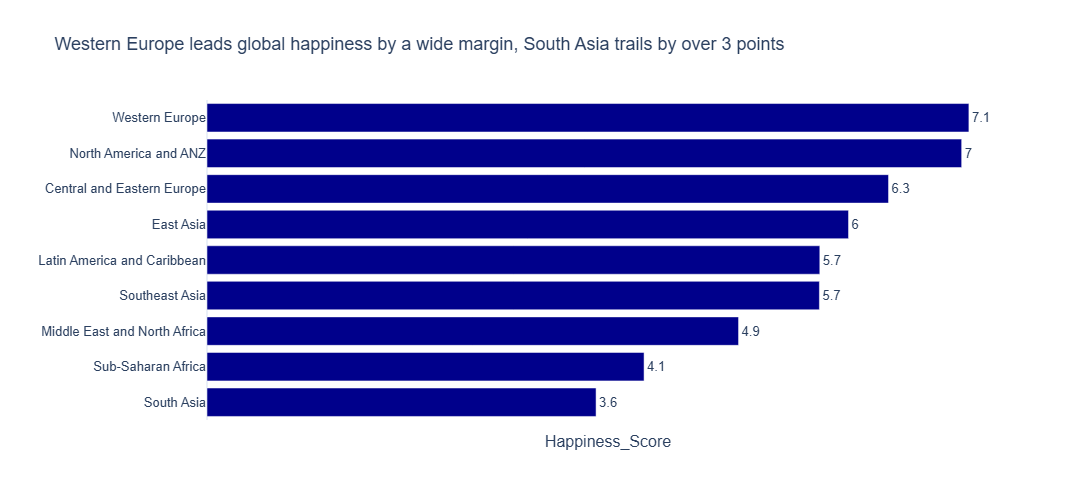

In [16]:
# prep data
region_avg = df.groupby('Region')['Happiness_Score'].mean().reset_index().sort_values('Happiness_Score')

# create a plotly express
fig = px.bar(
    data_frame=region_avg,
    x='Happiness_Score', 
    y='Region', orientation='h',
    text=region_avg['Happiness_Score'].round(1), # text over or inside the bars
    title='Western Europe leads global happiness by a wide margin, South Asia trails by over 3 points',
    labels={'Happiness Score': 'Happiness Score (1 - 10)', 'Region': ''},
    template='plotly_white',
    color_discrete_sequence=['darkblue']
)

# add needed customizations

fig.update_traces(
    textposition='outside', # controls where the text on the bars is positioned
)

fig.update_layout(
    xaxis=dict(showgrid=False, showticklabels=False),
    font=dict(family='Arial', size=13),
    height=500
)

fig.show()

---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81


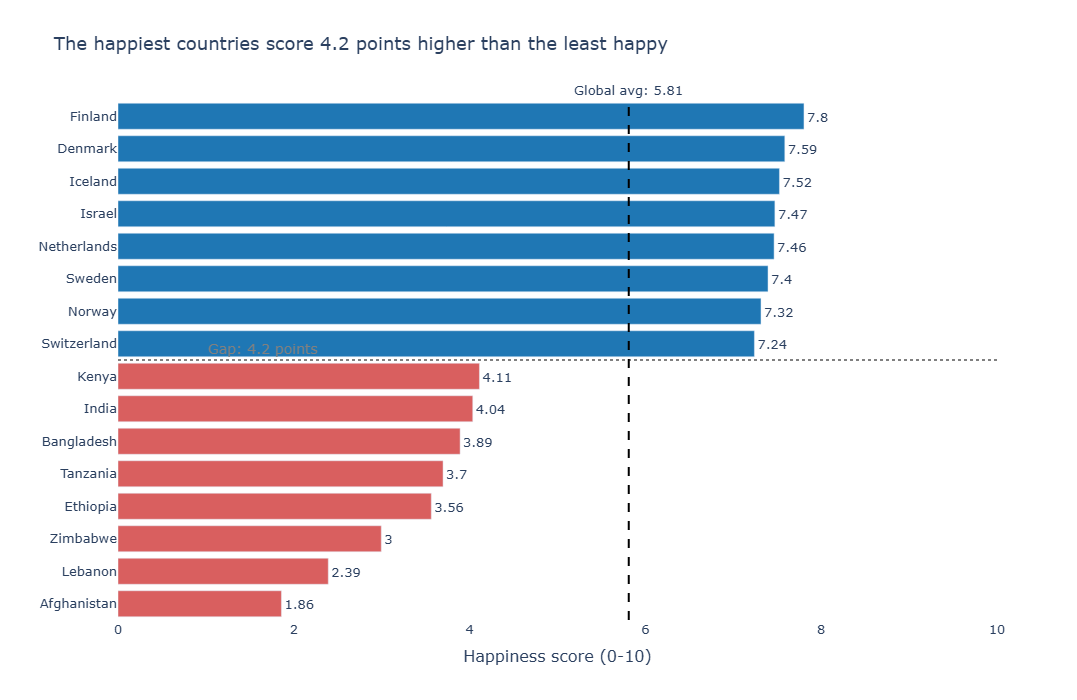

In [28]:
# Task 2: Top 8 vs. Bottom 8 contrast
# ------------------------------------

# Step 1: Get top and bottom countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()
print(f"Global average: {global_avg:.2f}")

# Step 2: Build your chart
gap = top8['Happiness_Score'].mean() - bottom8['Happiness_Score'].mean()

fig = go.Figure(go.Bar(
    x=combined['Happiness_Score'],
    y=combined['Country'],
    orientation='h',
    marker_color=combined['Group'].map({'Top 8': '#1F77B4', 'Bottom 8': '#D95F5F'}),
    text=combined['Happiness_Score'].round(2),
    textposition='outside',
))

# Visual separator between the bottom 8 and top 8
fig.add_hline(y=7.5, line_dash='dot', line_color='gray')

# Stretch: global average line
fig.add_vline(x=global_avg, line_dash='dash', line_color='black',
              annotation_text=f'Global avg: {global_avg:.2f}',
              annotation_position='top')

fig.add_annotation(x=1, y=7.5, text=f'Gap: {gap:.1f} points',
                   showarrow=False, font=dict(size=14, color='gray'),
                   xanchor='left', yanchor='bottom')

fig.update_layout(
    title=f"The happiest countries score {gap:.1f} points higher than the least happy",
    xaxis=dict(title='Happiness score (0-10)', range=[0, 10]),
    yaxis=dict(title=''),
    plot_bgcolor='White',
    font=dict(size=13),
    showlegend=False,
    height=700,
)
fig.show()



In [17]:
combined


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption,Group
60,Afghanistan,South Asia,1.859,6.180,0.374,47.5,0.382,-0.055,0.934,Bottom 8
61,Lebanon,Middle East and North Africa,2.392,7.650,0.486,60.5,0.444,0.049,0.874,Bottom 8
62,Zimbabwe,Sub-Saharan Africa,2.995,6.412,0.476,43.5,0.430,0.057,0.816,Bottom 8
52,Ethiopia,Sub-Saharan Africa,3.564,6.480,0.458,49.4,0.567,0.270,0.822,Bottom 8
53,Tanzania,Sub-Saharan Africa,3.698,6.936,0.525,52.4,0.600,0.258,0.797,Bottom 8
48,Bangladesh,South Asia,3.892,7.305,0.579,59.9,0.578,0.241,0.779,Bottom 8
47,India,South Asia,4.036,7.469,0.639,57.3,0.615,0.265,0.772,Bottom 8
50,Kenya,Sub-Saharan Africa,4.112,7.184,0.558,55.2,0.680,0.331,0.861,Bottom 8
7,Switzerland,Western Europe,7.240,11.117,0.942,74.1,0.921,0.244,0.283,Top 8
6,Norway,Western Europe,7.315,11.072,0.960,72.0,0.939,0.271,0.216,Top 8


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


In [13]:
# Stretch goal — grouped bar chart
# YOUR CODE HERE

